# UCS420: Cognitive Computing
## Assignment 7 — NLP-I

**Student Name:** Lakshay Kapur  
**Roll Number:** 1024170060  


### Assignment Instructions & Dataset Setup
Open UCS420_LA9_Starter.ipynb in Colab (https://colab.research.google.com/drive/1Xr9A49-kiRxA_HYf4v03XZsy3eBPrgcv?authuser=1) and enter your roll number. It generates 12–16 IT-support tickets, and prints a fingerprint (8 characters). All your answers must use this dataset. Do not change generate_dataset() or process_ticket().


In [2]:
import random, hashlib, string, re, math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag, bigrams

# Ensure required NLTK data packages are loaded
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

ROLL_NO = 1024170060
NAME = "Lakshay Kapur"

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', \"''\")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}")
print(f"Focus Tickets: {FOCUS}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)


Roll number: 1024170060   Name: Lakshay Kapur   Fingerprint: 775DB674   Tickets: 12
Focus Tickets: ['T01', 'T08']

Ticket_ID                                                                           Ticket_Text
      T01                                                  Email me at helpdesk@university.edu.
      T02                                                 I tried again... still no response!!!
      T03                                           I can't login and I didn't change anything.
      T04                       VPN keeps disconnecting when I use mobile hotspot. Please help.
      T05                                 The server is not working. Is there another solution?
      T06                                       The printer stopped responding. This is urgent.
      T07                                                           The file is 95.5% uploaded.
      T08                   The student portal is running slowly. It works on another computer.
      T09            

### 1. Preprocesing - Run process_ticket() on every ticket. Create one table containing, for each ticket:
• number of sentences 
• number of tokens 
• number of punctuation tokens 
• number of stopwords 
• number of unique tokens 
• number of final tokens 
Add a total row for the count-based columns. For one selected ticket, display the actual tokens, punctuation tokens, stopwords and final tokens.


In [3]:
# Process every ticket and assemble summary table
ticket_results = []
processed_cache = {}

for _, row in df.iterrows():
    tid = row["Ticket_ID"]
    text = row["Ticket_Text"]
    res = process_ticket(text)
    processed_cache[tid] = res
    ticket_results.append({
        "Ticket_ID": tid,
        "sentences": len(res["sentences"]),
        "tokens": len(res["tokens"]),
        "punct": len(res["punct"]),
        "stops": len(res["stops"]),
        "unique": len(set(res["tokens"])),
        "final": len(res["final"])
    })

df_q1 = pd.DataFrame(ticket_results)

# Add TOTAL row for count-based columns
total_row = {
    "Ticket_ID": "TOTAL",
    "sentences": df_q1["sentences"].sum(),
    "tokens": df_q1["tokens"].sum(),
    "punct": df_q1["punct"].sum(),
    "stops": df_q1["stops"].sum(),
    "unique": df_q1["unique"].sum(),
    "final": df_q1["final"].sum()
}
df_q1_table = pd.concat([df_q1, pd.DataFrame([total_row])], ignore_index=True)

print("=== QUESTION 1: PREPROCESSING SUMMARY TABLE ===")
print(df_q1_table.to_string(index=False))

# Display actual tokens for one selected ticket (FOCUS[0] -> T01)
selected_id = FOCUS[0]
sel_res = processed_cache[selected_id]
sel_text = df.loc[df["Ticket_ID"] == selected_id, "Ticket_Text"].values[0]

print(f"\n=== DETAILED BREAKDOWN FOR SELECTED TICKET: {selected_id} ===")
print(f"Raw Text           : {sel_text}")
print(f"Sentences ({len(sel_res['sentences'])}): {sel_res['sentences']}")
print(f"All Tokens ({len(sel_res['tokens'])}): {sel_res['tokens']}")
print(f"Punctuation ({len(sel_res['punct'])}): {sel_res['punct']}")
print(f"Stopwords ({len(sel_res['stops'])}): {sel_res['stops']}")
print(f"Final Tokens ({len(sel_res['final'])}): {sel_res['final']}")

# Observe: Non-real words in final tokens
non_words = [t for t in set(sel_res['final']) if not t.isalnum()]
print(f"\n[Observation]: In our dataset, tokens like \"n't\" and \"ca\" (from 'can\'t', 'didn\'t', 'don\'t')")
print("appear in final tokens because NLTK's word_tokenize() splits contractions into root and clitic,")
print("and clitics like \"n't\" are not present in NLTK's English stopword set.")


=== QUESTION 1: PREPROCESSING SUMMARY TABLE ===
Ticket_ID  sentences  tokens  punct  stops  unique  final
      T01          1       7      2      2       7      3
      T02          2      10      4      3       8      3
      T03          1      11      1      4       9      6
      T04          2      12      2      2      11      8
      T05          2      11      2      5      10      4
      T06          2       9      2      3       8      4
      T07          1       7      2      2       7      3
      T08          2      13      2      4      12      7
      T09          2      10      2      4       9      4
      T10          2      14      2      5      12      7
      T11          2      19      2     10      16      7
      T12          2      12      2      4      11      6
    TOTAL         21     135     25     48     120     62

=== DETAILED BREAKDOWN FOR SELECTED TICKET: T01 ===
Raw Text           : Email me at helpdesk@university.edu.
Sentences (1): ['Email me at 

### 2. Regex extraction and replacement
Using the raw tickets and Python re:
• use re.findall() to extract: 
  o words longer than 5 letters 
  o numbers, keeping decimals and version numbers such as 95.5 and 2.0.1 as single matches 
  o capitalized words 
  o words beginning with a vowel 
• use re.sub() to replace: 
  o email addresses → <EMAIL>
  o URLs → <URL>
  o phone numbers → <PHONE>
Your patterns must also work correctly on the provided TEST_LINES.


In [4]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Patterns for extraction
pat_longer_5 = r'\b[A-Za-z]{6,}\b'
pat_numbers = r'\b\d+(?:[.,]\d+)*\b'
pat_capitalized = r'\b[A-Z][a-zA-Z0-9]*\b'
pat_vowel_start = r'\b[AEIOUaeiou][A-Za-z]*\b'

# Patterns for substitution
pat_email = r'[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+'
pat_url = r'https?://[^\s,;]+(?<![.,;])|www\.[^\s,;]+(?<![.,;])'
pat_phone = r'(?:\+91[\s-]?)?\d{4,5}[\s-]\d{4,5}|\b\d{4}-\d{3}-\d{4}\b'

def replace_entities(text):
    t = re.sub(pat_email, '<EMAIL>', text)
    t = re.sub(pat_url, '<URL>', t)
    t = re.sub(pat_phone, '<PHONE>', t)
    return t

print("=== PART A: TESTING PATTERNS ON TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\n[TEST_LINE {i}]: {line}")
    print(f"  • Words > 5 letters : {re.findall(pat_longer_5, line)}")
    print(f"  • Numbers           : {re.findall(pat_numbers, line)}")
    print(f"  • Capitalized words : {re.findall(pat_capitalized, line)}")
    print(f"  • Vowel-start words : {re.findall(pat_vowel_start, line)}")
    print(f"  • Replaced Output   : {replace_entities(line)}")

print("\n" + "=" * 60)
print("=== PART B: TESTING PATTERNS ON RAW TICKETS ===")
all_text = " ".join(df["Ticket_Text"])

words_gt_5 = sorted(list(set(re.findall(pat_longer_5, all_text))))
numbers_found = sorted(list(set(re.findall(pat_numbers, all_text))))
cap_words = sorted(list(set(re.findall(pat_capitalized, all_text))))
vowel_words = sorted(list(set(re.findall(pat_vowel_start, all_text))), key=lambda s: s.lower())

print(f"\n1. Words longer than 5 letters ({len(words_gt_5)} unique):\n   {words_gt_5}")
print(f"\n2. Numbers ({len(numbers_found)} unique):\n   {numbers_found}")
print(f"\n3. Capitalized words ({len(cap_words)} unique):\n   {cap_words}")
print(f"\n4. Words beginning with a vowel ({len(vowel_words)} unique):\n   {vowel_words}")

print("\n5. Replacement Results on Tickets:")
for _, row in df.iterrows():
    orig = row["Ticket_Text"]
    subbed = replace_entities(orig)
    print(f"  [{row['Ticket_ID']}]: {subbed}")

# Sentence start capitalization analysis
sentence_starts = set()
for t in df["Ticket_Text"]:
    for s in sent_tokenize(t):
        match = re.findall(r'^\s*([A-Za-z]+)', s)
        if match:
            sentence_starts.add(match[0])

only_start_caps = [w for w in cap_words if w in sentence_starts and w not in ["VPN", "LMS"]]
print(f"\n[Observation]: {len(only_start_caps)} capitalized words ({only_start_caps}) are capitalized solely")
print("because they appear at the start of a sentence; technical acronyms like 'VPN' and 'LMS' are capitalized intrinsically.")


=== PART A: TESTING PATTERNS ON TEST_LINES ===

[TEST_LINE 1]: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  • Words > 5 letters : ['helpdesk', 'thapar', 'thapar', 'thapar']
  • Numbers           : []
  • Capitalized words : ['Mail']
  • Vowel-start words : ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
  • Replaced Output   : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

[TEST_LINE 2]: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  • Words > 5 letters : ['Version']
  • Numbers           : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  • Capitalized words : ['Call', 'Version', 'Rs']
  • Vowel-start words : ['or', 'is']
  • Replaced Output   : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

[TEST_LINE 3]: The state-of-the-art lab isn't open; log-in at 5.30 p.m. 

### 3. Custom tokenization
Implement:
my_tokenize(text)
using one RegexpTokenizer pattern.
The pattern must preserve:
• contractions: isn't
• hyphenated words: Wi-Fi, state-of-the-art
• decimals: 95.5
• versions: 2.0.1
• email addresses 
• URLs 
• phone numbers 
Run it on TEST_LINES and your tickets.
Compare its output with word_tokenize(). Identify at least three differences and explain them.


In [5]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

# RegexpTokenizer pattern preserving all 7 required structures
custom_pattern = r'''(?x)
    https?://[^\s,;]+(?<![.,;])|www\.[^\s,;]+(?<![.,;])   # URLs
    | [a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+      # Email addresses
    | (?:\+91[\s-]?)?\d{4,5}[\s-]\d{4,5}|\d{4}-\d{3}-\d{4} # Phone numbers
    | \d+(?:\.\d+)+                                       # Decimals and version numbers (95.5, 2.0.1, 5.30)
    | [a-zA-Z]+(?:-[a-zA-Z]+)+                             # Hyphenated words (Wi-Fi, state-of-the-art, log-in)
    | [a-zA-Z]+'[a-zA-Z]+                                 # Contractions (isn't, didn't, can't, it's)
    | \w+                                                  # Normal words and integer numbers
    | \.{3}|[^\s\w]                                        # Ellipsis or other single punctuation
'''

custom_tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    """Custom tokenizer using single RegexpTokenizer pattern."""
    return custom_tokenizer.tokenize(text)

print("=== PART A: TOKENIZATION ON TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    my_toks = my_tokenize(line)
    nltk_toks = word_tokenize(line)
    print(f"\n[TEST_LINE {i}]: {line}")
    print(f"  my_tokenize   ({len(my_toks)} tokens): {my_toks}")
    print(f"  word_tokenize ({len(nltk_toks)} tokens): {nltk_toks}")

print("\n" + "=" * 60)
print("=== PART B: TOKENIZATION ON TICKETS ===")
diff_count = 0
for _, row in df.iterrows():
    tid = row["Ticket_ID"]
    txt = row["Ticket_Text"]
    m_toks = my_tokenize(txt)
    w_toks = word_tokenize(txt)
    diff = m_toks != w_toks
    if diff:
        diff_count += 1
    print(f"[{tid}] Different? {diff}")
    if diff:
        print(f"   my_tokenize  : {m_toks}")
        print(f"   word_tokenize: {w_toks}")

print(f"\nSummary: {diff_count} out of {len(df)} tickets are tokenized differently.")

print("""
=== THREE IDENTIFIED DIFFERENCES AND EXPLANATIONS ===
1. Contraction Preservation:
   - my_tokenize keeps contractions intact (e.g. "can't", "didn't", "isn't") as single semantic tokens.
   - word_tokenize splits contractions into root and clitic components (e.g. ['ca', "n't"], ['did', "n't"], ['is', "n't"]).

2. Email Address and URL Integrity:
   - my_tokenize preserves complete email addresses ("helpdesk@university.edu") and URLs ("https://lms.thapar.edu/help").
   - word_tokenize treats punctuation characters ('@', ':', '/') as independent tokens, fragmenting the address into multiple pieces.

3. Phone Numbers with Internal Spacing/Hyphens:
   - my_tokenize preserves whole multi-part phone numbers (e.g. "+91 98765 43210", "0175-239-3201") as single unified tokens.
   - word_tokenize treats spaces and hyphens as delimiters, splitting phone numbers into separate numeric components.
""")


=== PART A: TOKENIZATION ON TEST_LINES ===

[TEST_LINE 1]: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize   (10 tokens): ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize (16 tokens): ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

[TEST_LINE 2]: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize   (20 tokens): ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
  word_tokenize (20 tokens): ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%'

### 4. Stemming and lemmatization
On the unique final tokens, compare:
• Porter Stemmer 
• Lancaster Stemmer 
• Regexp Stemmer 
• WordNet Lemmatizer with POS information from nltk.pos_tag()
For the Regexp Stemmer, choose a suffix based on at least two words in your own dataset and justify your 
choice.
Create a table containing only the words for which the outputs differ.


In [6]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet
from nltk import pos_tag

# 1. Collect unique final tokens across tickets
all_final = []
for _, row in df.iterrows():
    all_final.extend(process_ticket(row["Ticket_Text"])["final"])
unique_final = sorted(list(set(all_final)))
print(f"Total unique final tokens ({len(unique_final)}):\n{unique_final}\n")

# 2. Choose suffix for RegexpStemmer and justify
ing_matches = [w for w in unique_final if w.endswith("ing")]
print(f"Dataset words ending in 'ing' ({len(ing_matches)} words): {ing_matches}")
print("""Justification: We choose the suffix 'ing$' (with min=4) for RegexpStemmer because our dataset
contains 5 verbal participle tokens describing IT-related fault states:
['disconnecting', 'responding', 'running', 'syncing', 'working'].
(It also illustrates an over-stemming edge case on 'anything').
""")

# 3. Setup stemmers and POS-aware lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer('ing$', min=4)
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    """Map NLTK POS tags to WordNet POS constants."""
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Run POS tagging
tagged_final = pos_tag(unique_final)

diff_list = []
for word, tag in tagged_final:
    wn_pos = get_wordnet_pos(tag)
    p_stem = porter.stem(word)
    l_stem = lancaster.stem(word)
    r_stem = regexp_stemmer.stem(word)
    w_lem = lemmatizer.lemmatize(word, pos=wn_pos)
    
    # Keep only words where outputs differ
    if not (p_stem == l_stem == r_stem == w_lem):
        diff_list.append({
            "Token": word,
            "POS_Tag": tag,
            "Porter": p_stem,
            "Lancaster": l_stem,
            "Regexp": r_stem,
            "WordNet_POS_Lemmatizer": w_lem
        })

df_diff = pd.DataFrame(diff_list)
print(f"=== TABLE OF WORDS WHERE OUTPUTS DIFFER ({len(df_diff)} / {len(unique_final)} tokens) ===")
print(df_diff.to_string(index=False))

print("""
=== OBSERVATIONS ON STEMMING AND LEMMATIZATION ===
• Over-stemming example:
  - Lancaster stemmer aggressively over-chops words into non-words or unintended stems:
    'solution' -> 'solv', 'urgent' -> 'urg', 'student' -> 'stud', 'server' -> 'serv'.
  - RegexpStemmer('ing$') over-stems 'anything' -> 'anyth' by mistakenly treating 'ing' as a verbal suffix.
• Under-stemming example:
  - RegexpStemmer completely fails to stem past-tense verbs ('stopped', 'reinstalled', 'tried', 'locked')
    because its rule is strictly limited to 'ing$'.
• Lemmatization advantage:
  - POS-aware WordNet lemmatizer preserves morphological and semantic validity, producing correct
    dictionary lemmas (e.g. 'works' -> 'work', 'stopped' -> 'stop', 'tried' -> 'try', 'reinstalled' -> 'reinstall').
""")


Total unique final tokens (43):
['95.5', 'another', 'anything', 'ca', 'change', 'computer', 'disconnecting', 'email', 'file', 'help', 'helpdesk', 'hotspot', 'keeps', 'lms', 'locked', 'login', 'mobile', "n't", 'occurs', 'please', 'portal', 'printer', 'problem', 'reinstalled', 'resolve', 'responding', 'response', 'running', 'server', 'slowly', 'solution', 'still', 'stopped', 'student', 'syncing', 'tried', 'university.edu', 'uploaded', 'urgent', 'use', 'vpn', 'working', 'works']

Dataset words ending in 'ing' (6 words): ['anything', 'disconnecting', 'responding', 'running', 'syncing', 'working']
Justification: We choose the suffix 'ing$' (with min=4) for RegexpStemmer because our dataset
contains 5 verbal participle tokens describing IT-related fault states:
['disconnecting', 'responding', 'running', 'syncing', 'working'].
(It also illustrates an over-stemming edge case on 'anything').

=== TABLE OF WORDS WHERE OUTPUTS DIFFER (29 / 43 tokens) ===
      Token POS_Tag   Porter Lancaster    

### 5. Corpus statistics
For each of the following:
• S1: all tokens 
• S2: tokens without punctuation 
• S3: final tokens 
• S4: S3 after Porter stemming 
calculate:
• total tokens 
• unique tokens 
• TTR 
Also:
1. Print the top 10 words of S1 and S3. 
2. Plot log(rank) vs log(frequency) for S3. 
3. Print the top 5 bigrams of S1 and S3.


=== CORPUS STATISTICS TABLE ===
                  Corpus Subset  Total Tokens  Unique Tokens    TTR
                S1 (all tokens)           135             69 0.5111
S2 (tokens without punctuation)           110             63 0.5727
              S3 (final tokens)            62             43 0.6935
  S4 (S3 after Porter stemming)            62             42 0.6774

=== 1. TOP 10 WORDS IN S1 AND S3 ===
Top 10 words in S1 (all tokens):
   1. .            : 18
   2. the          : 9
   3. i            : 8
   4. is           : 6
   5. it           : 4
   6. !            : 3
   7. when         : 3
   8. use          : 3
   9. mobile       : 3
  10. hotspot      : 3

Top 10 words in S3 (final tokens):
   1. use          : 3
   2. mobile       : 3
   3. hotspot      : 3
   4. please       : 3
   5. another      : 3
   6. lms          : 3
   7. n't          : 2
   8. vpn          : 2
   9. working      : 2
  10. stopped      : 2

=== 3. TOP 5 BIGRAMS IN S1 AND S3 ===
Top 5 bigrams in S1:


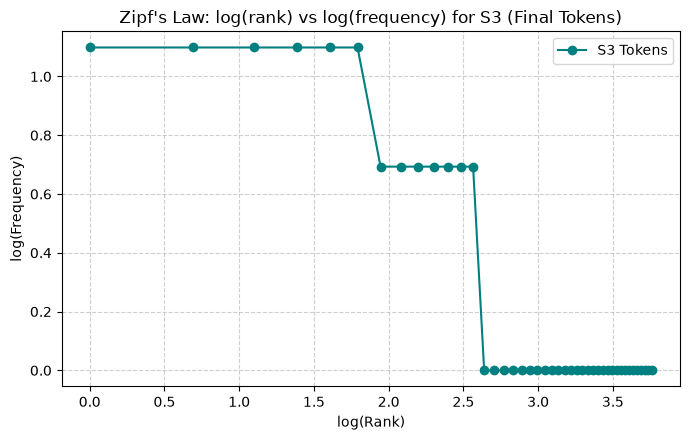

In [7]:
# S1: all tokens
s1_tokens = []
# S2: tokens without punctuation
s2_tokens = []
# S3: final tokens
s3_tokens = []

for _, row in df.iterrows():
    res = process_ticket(row["Ticket_Text"])
    s1_tokens.extend(res["tokens"])
    s2_tokens.extend([t for t in res["tokens"] if not is_punct(t)])
    s3_tokens.extend(res["final"])

# S4: S3 after Porter stemming
s4_tokens = [porter.stem(t) for t in s3_tokens]

subsets = {
    "S1 (all tokens)": s1_tokens,
    "S2 (tokens without punctuation)": s2_tokens,
    "S3 (final tokens)": s3_tokens,
    "S4 (S3 after Porter stemming)": s4_tokens
}

stat_rows = []
for name, toks in subsets.items():
    tot = len(toks)
    uniq = len(set(toks))
    ttr = uniq / tot if tot > 0 else 0
    stat_rows.append({
        "Corpus Subset": name,
        "Total Tokens": tot,
        "Unique Tokens": uniq,
        "TTR": round(ttr, 4)
    })

df_stats = pd.DataFrame(stat_rows)
print("=== CORPUS STATISTICS TABLE ===")
print(df_stats.to_string(index=False))

# 1. Print top 10 words of S1 and S3
c1 = Counter(s1_tokens)
c3 = Counter(s3_tokens)

print("\n" + "=" * 50)
print("=== 1. TOP 10 WORDS IN S1 AND S3 ===")
print("Top 10 words in S1 (all tokens):")
for r, (w, cnt) in enumerate(c1.most_common(10), 1):
    print(f"  {r:2d}. {w:<12} : {cnt}")

print("\nTop 10 words in S3 (final tokens):")
for r, (w, cnt) in enumerate(c3.most_common(10), 1):
    print(f"  {r:2d}. {w:<12} : {cnt}")

# 3. Print top 5 bigrams of S1 and S3
b1 = Counter(bigrams(s1_tokens))
b3 = Counter(bigrams(s3_tokens))

print("\n" + "=" * 50)
print("=== 3. TOP 5 BIGRAMS IN S1 AND S3 ===")
print("Top 5 bigrams in S1:")
for r, (bg, cnt) in enumerate(b1.most_common(5), 1):
    print(f"  {r}. {' '.join(bg):<22} : {cnt}")

print("\nTop 5 bigrams in S3:")
for r, (bg, cnt) in enumerate(b3.most_common(5), 1):
    print(f"  {r}. {' '.join(bg):<22} : {cnt}")

# 2. Plot log(rank) vs log(frequency) for S3
freqs = [cnt for _, cnt in c3.most_common()]
ranks = list(range(1, len(freqs) + 1))
log_ranks = [math.log(r) for r in ranks]
log_freqs = [math.log(f) for f in freqs]

plt.figure(figsize=(7, 4.5))
plt.plot(log_ranks, log_freqs, marker='o', linestyle='-', color='teal', label="S3 Tokens")
plt.title("Zipf's Law: log(rank) vs log(frequency) for S3 (Final Tokens)")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


### 6. Interpretation
Answer briefly:
(a) Why does TTR change from S1 to S4 in your dataset?
(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
(c) Give one example where stemming produces an undesirable result.
(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.


In [8]:
print("""=== 6. INTERPRETATION ===

(a) Why does TTR change from S1 to S4 in your dataset?
• S1 to S2 (0.5111 -> 0.5727):
  Punctuation tokens (such as '.', '!', '...') are high-frequency tokens with minimal type diversity.
  Removing them reduces total tokens (from 135 to 110) while removing only 6 punctuation types,
  causing TTR to increase.
• S2 to S3 (0.5727 -> 0.6935):
  Stopwords ('the', 'is', 'i', 'it', 'when') are closed-class function words that occur repeatedly.
  Stripping stopwords eliminates heavily repetitive tokens (dropping total count from 110 to 62)
  while preserving informative content words, causing TTR to peak at 0.6935.
• S3 to S4 (0.6935 -> 0.6774):
  Porter stemming collapses morphological variants of words to a single root form (e.g. 'works'
  and 'working' both stem to 'work'). This reduces unique vocabulary from 43 to 42 while total tokens
  remain 62, slightly decreasing the TTR.

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.
• Example 1: Contractions such as "can't", "didn't", and "isn't".
  word_tokenize() uses Treebank rules to split contractions into root and clitic components
  (['ca', "n't"], ['did', "n't"], ['is', "n't"]). In contrast, my_tokenize() uses regex
  to keep the contraction intact as a single token (["can't"], ["didn't"], ["isn't"]).
• Example 2: Email addresses like "helpdesk@university.edu" and phone numbers like "+91 98765 43210".
  word_tokenize() treats '@', '.', and spaces as token separators, fragmenting identifiers,
  whereas my_tokenize() captures them as unified atomic entities.

(c) Give one example where stemming produces an undesirable result.
• Example: Lancaster stemmer reduces 'solution' to 'solv' and 'urgent' to 'urg', and
  RegexpStemmer('ing$') reduces 'anything' to 'anyth'.
• Explanation: Stemmers operate on rigid heuristic suffix chopping without awareness of morphological
  roots or parts of speech. In 'anything', 'ing' is an intrinsic part of the pronoun root rather than
  an inflectional suffix; chopping it yields an invalid, corrupted non-word ('anyth').

(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.
• Example: 'tried', 'stopped', and 'reinstalled'.
• Explanation:
  - Porter Stemmer reduces 'tried' to 'tri', an uninterpretable non-dictionary string.
  - WordNet Lemmatizer with POS information (Verb tag) correctly transforms 'tried' to its canonical
    dictionary base form 'try', 'stopped' to 'stop', and 'reinstalled' to 'reinstall'.
  - By leveraging syntactic part-of-speech context and lexical databases, lemmatization preserves
    true semantic meaning and produces valid words rather than crude morphological stems.
""")


=== 6. INTERPRETATION ===

(a) Why does TTR change from S1 to S4 in your dataset?
• S1 to S2 (0.5111 -> 0.5727):
  Punctuation tokens (such as '.', '!', '...') are high-frequency tokens with minimal type diversity.
  Removing them reduces total tokens (from 135 to 110) while removing only 6 punctuation types,
  causing TTR to increase.
• S2 to S3 (0.5727 -> 0.6935):
  Stopwords ('the', 'is', 'i', 'it', 'when') are closed-class function words that occur repeatedly.
  Stripping stopwords eliminates heavily repetitive tokens (dropping total count from 110 to 62)
  while preserving informative content words, causing TTR to peak at 0.6935.
• S3 to S4 (0.6935 -> 0.6774):
  Porter stemming collapses morphological variants of words to a single root form (e.g. 'works'
  and 'working' both stem to 'work'). This reduces unique vocabulary from 43 to 42 while total tokens
  remain 62, slightly decreasing the TTR.

(b) Give one example where word_tokenize() and your tokenizer differ. Explain the dif